# Comparing the Python Model with SEBE
Comparing the yearly sunlight from our simplified Python model with the results from SEBE, for rooftops in Sandy Bay and Howrah.

**Inputs**
- Yearly sunlight from the Python model for each test area (from notebook 02)
- Yearly sunlight from SEBE for each test area (run in QGIS)
- Building footprints for each test area (from notebook 01)
- Slope, aspect and roughness for each test area (from notebook 02)

## Setup

Importing the libraries and setting the folders used through the notebook.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.features import rasterize
from rasterio.plot import plotting_extent

# Project folders
inpath = Path("/Users/lailamclennan/Documents/CODING/AT3/Inputs")
outpath = Path("/Users/lailamclennan/Documents/CODING/AT3/Outputs")

## 1. Read in the Python model results

Reading in the yearly sunlight rasters that were saved at the end of notebook 02. This means the model does not need to be run again here.

In [2]:
# For each area open the file, read the yearly sunlight into an
# array, keep the grid details for later, and close the file

# West (Sandy Bay)
west_file = rasterio.open(outpath / "West_yearly_sunlight.tif")
west_model = west_file.read(1)
west_profile = west_file.profile
west_file.close()

# East (Howrah)
east_file = rasterio.open(outpath / "East_yearly_sunlight.tif")
east_model = east_file.read(1)
east_profile = east_file.profile
east_file.close()

# Map coordinates of each raster's edges, so every plot can show
# eastings and northings
west_extent = plotting_extent(west_model, west_profile["transform"])
east_extent = plotting_extent(east_model, east_profile["transform"])

## 2. Read in the data

Reading in the yearly sunlight from our model, the slope, and the building footprints for each test area.

In [2]:
# Yearly sunlight from the Python model, in kWh/m2.
# For each area open the file, read the values into an array, keep the
# grid details for saving later, then close the file

# West (Sandy Bay)
west_file = rasterio.open(outpath / "West_yearly_sunlight.tif")
west_model = west_file.read(1)
west_profile = west_file.profile
west_file.close()

# East (Howrah)
east_file = rasterio.open(outpath / "East_yearly_sunlight.tif")
east_model = east_file.read(1)
east_profile = east_file.profile
east_file.close()

# Map extents so the plots show eastings and northings
west_extent = plotting_extent(west_model, west_profile["transform"])
east_extent = plotting_extent(east_model, east_profile["transform"])

In [3]:
# Slope of each pixel, in degrees

# West (Sandy Bay)
west_slope_file = rasterio.open(outpath / "West_slope.tif")
west_slope = west_slope_file.read(1)
west_slope_file.close()

# East (Howrah)
east_slope_file = rasterio.open(outpath / "East_slope.tif")
east_slope = east_slope_file.read(1)
east_slope_file.close()

In [4]:
# Building footprints for each test area. The placeholder squares were
# already removed in notebook 01
west_buildings = gpd.read_file(outpath / "Buildings_West.shp")
east_buildings = gpd.read_file(outpath / "Buildings_East.shp")

print("West buildings:", len(west_buildings))
print("East buildings:", len(east_buildings))

West buildings: 484
East buildings: 257


## 3. Roof mask

Turning the building footprints into a grid that matches the rasters, where True means the pixel is inside a building.

In [5]:
# Turn the building polygons into a grid that matches the rasters.
# Pixels inside a building get 1 and everything else gets 0

# West (Sandy Bay)
west_grid = rasterize(
    west_buildings.geometry,
    out_shape=west_model.shape,
    transform=west_profile["transform"],
)

# East (Howrah)
east_grid = rasterize(
    east_buildings.geometry,
    out_shape=east_model.shape,
    transform=east_profile["transform"],
)

# Turn the 1s and 0s into True and False, so True means roof
west_roofs = west_grid == 1
east_roofs = east_grid == 1

# Check how much of each area is roof
print("West area covered by roofs:", round(west_roofs.mean() * 100), "%")
print("East area covered by roofs:", round(east_roofs.mean() * 100), "%")

West area covered by roofs: 21 %
East area covered by roofs: 13 %


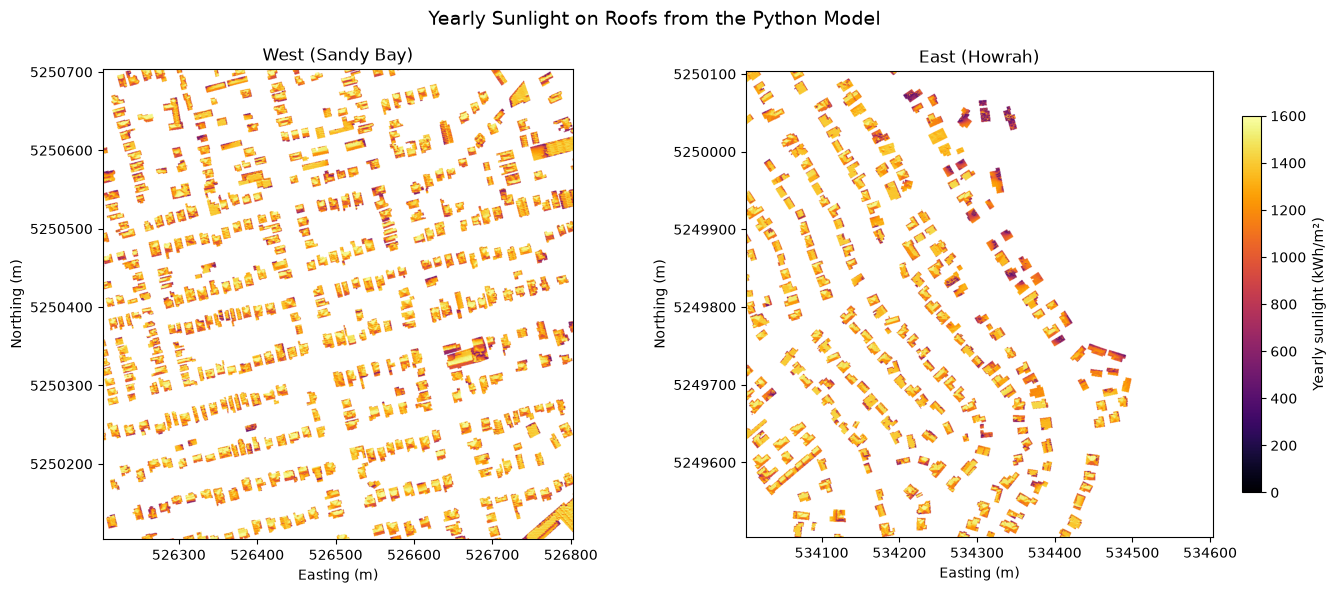

In [8]:
# Keep the model value where there is a roof and leave the rest blank,
# to check the footprints line up with the buildings
west_roofs_only = np.where(west_roofs, west_model, np.nan)
east_roofs_only = np.where(east_roofs, east_model, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# West (Sandy Bay)
west_plot = axes[0].imshow(
    west_roofs_only, cmap="inferno", vmin=0, vmax=1600, extent=west_extent
)
axes[0].set_title("West (Sandy Bay)")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")
# Show full coordinates and not scientific notation
axes[0].ticklabel_format(style="plain", useOffset=False)

# East (Howrah)
east_plot = axes[1].imshow(
    east_roofs_only, cmap="inferno", vmin=0, vmax=1600, extent=east_extent
)
axes[1].set_title("East (Howrah)")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")
axes[1].ticklabel_format(style="plain", useOffset=False)

# One colourbar covers both maps because they share the same scale
fig.colorbar(
    east_plot, ax=axes[1], label="Yearly sunlight (kWh/m²)", shrink=0.8
)

fig.suptitle("Yearly Sunlight on Roofs from the Python Model", fontsize=14)
plt.tight_layout()
fig.savefig("Images/yearly_sunlight_roofs.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Suitability criteria

A roof pixel is suitable for a solar panel if it passes all three rules:

| Rule | Limit | Source |
|---|---|---|
| On a building | Inside a building footprint | LIST building footprints |
| Not a wall | Slope of 65° or less | UMEP SEBE tutorial |
| Enough sun | At least 80% of the yearly sunlight on unshaded flat ground | Roberts, Copper and Bruce (2018) |

There is no separate rule for aspect or shading. South-facing and shaded pixels get less sun, so they fail the sunlight rule.

In [9]:
# Steepest slope that still counts as roof and not wall, in degrees
max_slope = 65

# Yearly sunlight on unshaded flat ground, which is the yearly GHI
# from the weather file (notebook 01)
flat_ground_sunlight = 1424

# A pixel needs at least 80% of that to count as getting enough sun
min_sunlight = 0.8 * flat_ground_sunlight

print("Minimum yearly sunlight:", round(min_sunlight), "kWh/m2")

Minimum yearly sunlight: 1139 kWh/m2


In [10]:
# A pixel is suitable if it is on a roof, is not a wall and gets
# enough sun. The & means all three have to be true

# West (Sandy Bay)
west_suitable = (
    west_roofs & (west_slope <= max_slope) & (west_model >= min_sunlight)
)

# East (Howrah)
east_suitable = (
    east_roofs & (east_slope <= max_slope) & (east_model >= min_sunlight)
)

In [11]:
# Each pixel is 0.5 m x 0.5 m, so it covers 0.25 m2
pixel_area = 0.25

# Count the pixels and turn the count into an area
west_roof_area = west_roofs.sum() * pixel_area
west_suitable_area = west_suitable.sum() * pixel_area
east_roof_area = east_roofs.sum() * pixel_area
east_suitable_area = east_suitable.sum() * pixel_area

print("West roof area:", round(west_roof_area), "m2")
print("West suitable area:", round(west_suitable_area), "m2")
print("East roof area:", round(east_roof_area), "m2")
print("East suitable area:", round(east_suitable_area), "m2")

West roof area: 76412 m2
West suitable area: 53279 m2
East roof area: 45217 m2
East suitable area: 30504 m2


## 5. Map of suitable roof area

Suitable roof is shown in orange and the rest of the roof in grey.

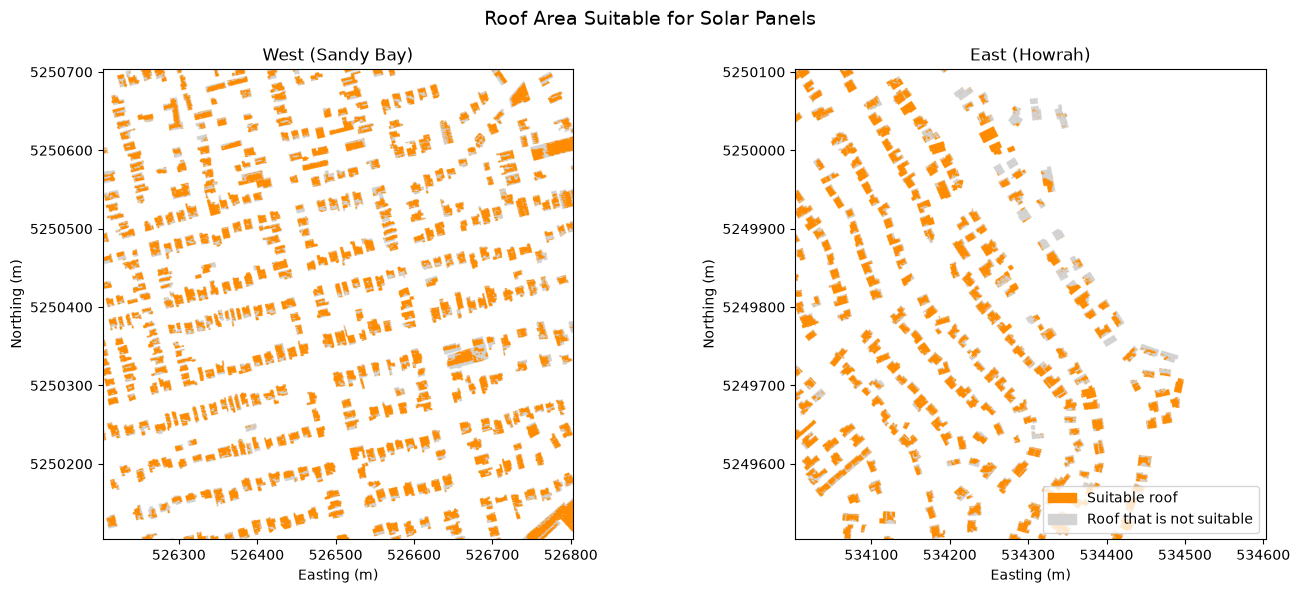

In [13]:
# Give each roof pixel a class: 1 for roof that is not suitable and
# 2 for suitable roof. Pixels that are not roof are left blank
west_classes = np.where(west_roofs, 1.0, np.nan)
west_classes[west_suitable] = 2

east_classes = np.where(east_roofs, 1.0, np.nan)
east_classes[east_suitable] = 2

# Grey for class 1 and orange for class 2
colours = ListedColormap(["lightgrey", "darkorange"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# West (Sandy Bay)
axes[0].imshow(
    west_classes, cmap=colours, vmin=1, vmax=2, extent=west_extent
)
axes[0].set_title("West (Sandy Bay)")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")
axes[0].ticklabel_format(style="plain", useOffset=False)

# East (Howrah)
axes[1].imshow(
    east_classes, cmap=colours, vmin=1, vmax=2, extent=east_extent
)
axes[1].set_title("East (Howrah)")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")
axes[1].ticklabel_format(style="plain", useOffset=False)

# A legend with one box for each class
legend_boxes = [
    Patch(color="darkorange", label="Suitable roof"),
    Patch(color="lightgrey", label="Roof that is not suitable"),
]
axes[1].legend(handles=legend_boxes, loc="lower right")

fig.suptitle("Roof Area Suitable for Solar Panels", fontsize=14)
plt.tight_layout()
fig.savefig("Images/suitable_roof_area.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Save the results

Saving the suitable roof pixels as a raster (1 for suitable, 0 for not), so they can be opened in QGIS.

In [14]:
# Use the same grid details as the model results, but store the values
# as whole numbers
west_profile.update(dtype="uint8", nodata=None)
east_profile.update(dtype="uint8", nodata=None)

# West (Sandy Bay)
# Create the file, write the values into band 1, then close it
west_path = outpath / "West_suitable.tif"
west_output = rasterio.open(west_path, "w", **west_profile)
west_output.write(west_suitable.astype("uint8"), 1)
west_output.close()

# East (Howrah)
east_path = outpath / "East_suitable.tif"
east_output = rasterio.open(east_path, "w", **east_profile)
east_output.write(east_suitable.astype("uint8"), 1)
east_output.close()

print("Suitable roof files saved")

Suitable roof files saved


## Summary

About two thirds of the roof area in both test areas passes the criteria. The suitable roof pixels are saved in the Outputs folder as `West_suitable.tif` and `East_suitable.tif`.